<a href="https://colab.research.google.com/github/sreeparvathitk/python-projects/blob/main/titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.weightstats import ztest

In [5]:
df=pd.read_csv(r"/content/titanic.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [6]:
df.shape

(891, 12)

In [7]:
#Renaming columns
df.rename(columns={"SibSp":"sibsp", "Survived":"survived","Pclass":"pclass","Sex":"sex","SibSb":"sibsb","Parch":"parch","Fare":"fare","Cabin":"cabin","Embarked":"embarked","Age":"age"}, inplace=True)


In [8]:
df.columns


Index(['PassengerId', 'survived', 'pclass', 'Name', 'sex', 'age', 'sibsp',
       'parch', 'Ticket', 'fare', 'cabin', 'embarked'],
      dtype='object')

In [9]:
df.drop(["PassengerId","Name"	,	"Ticket"],axis=1,inplace=True)


In [10]:
#to check duplicate rows and missing values
def preprocessing (data):
  print(f"duplicates counts: {df.duplicated().sum()}")
  print(f"nullvalue  counts:\n{df.isna().sum()}")

preprocessing(df)


duplicates counts: 107
nullvalue  counts:
survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
cabin       687
embarked      2
dtype: int64


In [11]:
#Counts the missing values in each column
df.isna().mean()*100

,0
survived,0.000000
pclass,0.000000
sex,0.000000
age,19.865320
sibsp,0.000000
parch,0.000000
fare,0.000000
cabin,77.104377
embarked,0.224467


In [12]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    object 
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   cabin     204 non-null    object 
 8   embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(3)
memory usage: 62.8+ KB


In [13]:
#Counting the values in selected columns
columns=["sex","pclass", "embarked","survived", "sibsp","parch"]
for i in columns:
  print(f" {i} : {pd.unique(df[i])}")

 sex : ['male' 'female']
 pclass : [3 1 2]
 embarked : ['S' 'C' 'Q' nan]
 survived : [0 1]
 sibsp : [1 0 3 4 2 5 8]
 parch : [0 1 2 5 3 4 6]


In [14]:
#Finding unique values in each column
for i in columns:
  print(f"{i} : {df[i].value_counts()}\n")


sex : sex
male      577
female    314
Name: count, dtype: int64

pclass : pclass
3    491
1    216
2    184
Name: count, dtype: int64

embarked : embarked
S    644
C    168
Q     77
Name: count, dtype: int64

survived : survived
0    549
1    342
Name: count, dtype: int64

sibsp : sibsp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

parch : parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64



In [15]:
#updating embarked columns
df.loc[df["embarked"]=="C","embarked"]="Cherbourg"
df.loc[df["embarked"]=="Q","embarked"]="Queenstown"
df.loc[df["embarked"]=="S","embarked"]="Southampton"
df["embarked"]

,embarked
0,Southampton
1,Cherbourg
2,Southampton
3,Southampton
4,Southampton
...,...
886,Southampton
887,Southampton
888,Southampton
889,Cherbourg


In [16]:
#statistical summary of the numerical columns
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Text(0, 0.5, 'Passengers Value Count ')

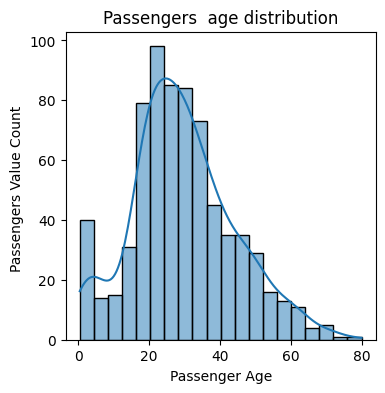

In [17]:
#distribution of passenger age
plt.figure(figsize=(4,4))
sns.histplot(df["age"], kde=True)
plt.title("Passengers  age distribution")
plt.xlabel("Passenger Age")
plt.ylabel("Passengers Value Count ")


Text(0, 0.5, 'Passengers Age')

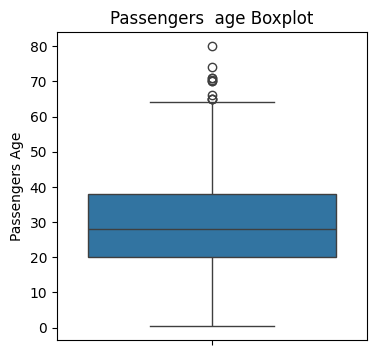

In [18]:
plt.figure(figsize=(4,4))
sns.boxplot(df["age"])
plt.title("Passengers  age Boxplot")
plt.ylabel("Passengers Age")

In [19]:
df.fillna({"age":df["age"].median(),"embarked":df["embarked"].mode()[0],},inplace=True)

Text(0, 0.5, 'Number of Passengers')

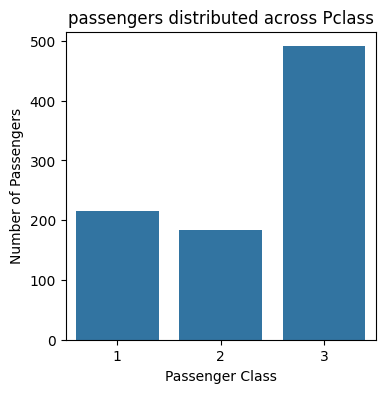

In [20]:
# passengers distributed across the different passenger classes (Pclass)
plt.figure(figsize=(4,4))
sns.countplot(data=df, x="pclass")
plt.title("passengers distributed across Pclass")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

Text(0.5, 0, 'Number of parents/child')

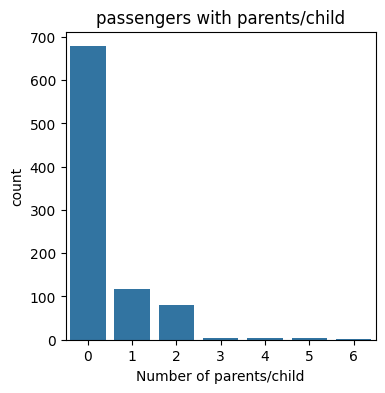

In [21]:
# passengers had parents/children (Parch)
plt.figure(figsize=(4,4))
sns.countplot(data=df, x=df["parch"])
plt.title("passengers with parents/child")
plt.ylabel("count")
plt.xlabel("Number of parents/child")

Text(0.5, 0, 'Number of siblings/spouses')

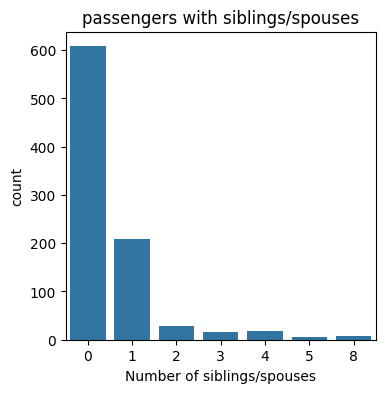

In [22]:
#passengers had siblings/spouses (SibSp)
plt.figure(figsize=(4,4))
sns.countplot(data=df, x=df["sibsp"])
plt.title("passengers with siblings/spouses")
plt.ylabel("count")
plt.xlabel("Number of siblings/spouses")

In [23]:
#passengers were traveling alone
df[(df['parch']==0) & (df['sibsp']==0)]



,survived,pclass,sex,age,sibsp,parch,fare,cabin,embarked
2,1,3,female,26.0,0,0,7.9250,NaN,Southampton
4,0,3,male,35.0,0,0,8.0500,NaN,Southampton
5,0,3,male,28.0,0,0,8.4583,NaN,Queenstown
6,0,1,male,54.0,0,0,51.8625,E46,Southampton
11,1,1,female,58.0,0,0,26.5500,C103,Southampton
...,...,...,...,...,...,...,...,...,...
884,0,3,male,25.0,0,0,7.0500,NaN,Southampton
886,0,2,male,27.0,0,0,13.0000,NaN,Southampton
887,1,1,female,19.0,0,0,30.0000,B42,Southampton
889,1,1,male,26.0,0,0,30.0000,C148,Cherbourg


Text(0.5, 0, 'Gender')

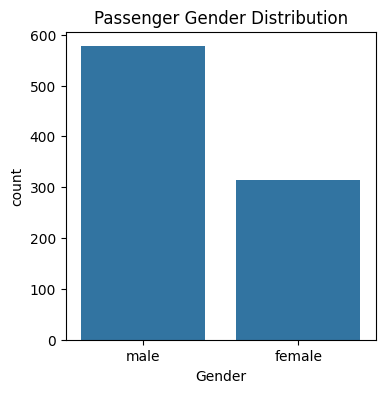

In [24]:
#passengers gender distribution
plt.figure(figsize=(4,4))
sns.countplot(data=df, x="sex")
plt.title("Passenger Gender Distribution")
plt.ylabel("count")
plt.xlabel("Gender")